# Equity Data Preparation
Build US equity research inputs from raw CRSP (2014–2025), Compustat and CCM downloads. Prices include total returns; the target enters at the next close and exits ten trading sessions later: $y_{i,t}=P^{adj}_{i,t+11}/P^{adj}_{i,t+1}-1$.

## 1. Setup
Raw inputs remain unchanged. Each run creates a new dataset and audit trail.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/usq').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from usq.database.common import digest, save_parquet
from usq.database.wrds_reconstruction import inventory, new_output, prepare_links, interval_segments
from usq.database.raw_preparation import (audit_market_sources, build_financial_events,
    build_industry_events, build_universe, audit_published_prices)
from usq.database.strategy_snapshot import publish_strategy_snapshot, activate_snapshot
from usq.database.sina_validation import probe_sina
from usq.data.adjustments import PRICE_PRECISION_POLICY

DATA_ROOT = ROOT / 'data'
RAW = DATA_ROOT / 'raw/wrds'
QUARTERLY = DATA_ROOT / 'raw/compustat/quarterly/Comp_Quarterly6126.csv.zip'
ANNUAL = DATA_ROOT / 'raw/compustat/annual/20250102updated north fundamental_dta.zip'
OUT = new_output(ROOT / 'runs')
# Activate inputs only after every preparation stage succeeds.
(DATA_ROOT / 'processed/latest_snapshot.json').unlink(missing_ok=True)
print('Output:', OUT)


Output: /Users/utastn/Desktop/Files/学习资料/NUS/DSA5205/DSA5205_Project2/release/DSA5205_Project2_Freya/runs/wrds_20261111_134234_590623


## 2. Source Inventory
Record file schemas, row counts and SHA-256 hashes before processing.

In [2]:
sources = inventory(RAW)
archives = pd.DataFrame([{'file': p.name, 'bytes': p.stat().st_size,
    'rows': pd.NA, 'columns': scope, 'sha256': digest(p)}
    for p, scope in [(QUARTERLY, 'North America quarterly fundamentals'),
                     (ANNUAL, 'North America annual industry history')]])
sources = pd.concat([sources, archives], ignore_index=True)
sources.to_csv(OUT / 'source_inventory.csv', index=False)
display(sources[['file', 'rows', 'bytes', 'sha256']])


,file,rows,bytes,sha256
0,crsp_dsedelist.parquet,38872,2108910,982479070c4bc15b3a9bdae37add9677c219d0a07b3dc8...
1,crsp_dsenames.parquet,117859,4371082,b3f63d74d9804833fd952fb13b76f3447454af10a72d59...
2,crsp_dsf_2014_2024.parquet,22310670,849221799,11ef6a358e788c5895002a0baade9c70113506bd4a4cc4...
3,crsp_dsf_v2_2025.parquet,2541801,111746042,a7c4b26b88e0c4dd9629a20602542bf093a4194d877e78...
4,compustat_company.parquet,58724,2873641,fa88449e326a0bce35af79ca69a0642243cdca9a96c9d6...
5,compustat_funda_2014_2026.parquet,144943,9790112,baafa8a7ea5df0795d73759e4b9ea736a97441e4d69028...
6,compustat_fundq_2014_2026.parquet,615027,30852225,d67abdde62e7907c618279460a086d6833de5ce074e302...
7,crsp_ccmxpf_linktable.parquet,92711,1421701,cee3008146d92055b94f5a043094c7f2b8347e0f4c6245...
8,Comp_Quarterly6126.csv.zip,<NA>,749232482,27ea52eb9c1d7a5e2a96c18af2e4d7fad1bbfc8322a035...
9,20250102updated north fundamental_dta.zip,<NA>,411461995,f7f82b3c6e8fc2aa726f7125929dcfa750447160922c65...


## 3. Market Data Quality
Negative PRC denotes a quote mark. Material OHLC errors exceed both $0.01001 and 0.1% of close; affected research bars are quarantined. Share counts are converted from thousands to shares.

In [3]:
quality, anomalies = audit_market_sources(RAW, OUT)
display(quality.set_index('file'))
display(anomalies.head(10))
assert quality.duplicate_keys.sum() == 0
assert quality.negative_volume.sum() == 0


,rows,quote_marks,missing_or_zero_close,negative_volume,zero_volume,material_OHLC,duplicate_keys
file,,,,,,,
crsp_dsf_2014_2024.parquet,22310670,606686,107721,0,453492,8,0
crsp_dsf_v2_2025.parquet,2541801,0,3775,0,25094,0,0


,date,permno,prc,openprc,askhi,bidlo,vol,source_file
0,2014-12-16,90232,10.12,1.02,10.730,9.7500,41337.0,crsp_dsf_2014_2024.parquet
1,2023-06-05,11762,183.59,186.38,185.630,183.2000,1769410.0,crsp_dsf_2014_2024.parquet
2,2023-06-05,12540,9.22,9.07,9.320,9.1100,681387.0,crsp_dsf_2014_2024.parquet
3,2023-06-05,13103,92.27,93.67,93.070,91.9950,1758253.0,crsp_dsf_2014_2024.parquet
4,2023-06-05,14144,13.14,13.40,13.300,13.0399,8346833.0,crsp_dsf_2014_2024.parquet
5,2023-06-05,20126,5.99,5.72,6.090,5.7600,6306127.0,crsp_dsf_2014_2024.parquet
6,2023-06-05,45356,61.79,62.48,62.170,61.4210,3067271.0,crsp_dsf_2014_2024.parquet
7,2023-06-05,92157,124.20,125.96,125.835,123.8650,967656.0,crsp_dsf_2014_2024.parquet


## 4. Security Mapping
Use dated CCM GVKEY/LIID–PERMNO links, never ticker joins. Reject conflicting overlaps. FIC/PRIUSA are static descriptors; 2025 CIZ lacks some historical classification flags.

In [4]:
links = prepare_links(RAW)
segments, conflicts = interval_segments(links, 'permno', 'linkdt', 'linkenddt', ['sid'])
save_parquet(links, OUT / 'dated_ccm_links.parquet')
conflicts.to_csv(OUT / 'ambiguous_ccm_intervals.csv', index=False)
display(links.groupby(['linktype', 'linkprim']).size().rename('links').to_frame())
display(links[['sid', 'permno', 'linkdt', 'linkenddt']].head())
assert conflicts.empty


links
linktype linkprim       
LC       C           637
         J           175
         N            35
         P          9050
LS       C           181
         P          6628
LU       C           117
         J            10
         P          1468

,sid,permno,linkdt,linkenddt
14,CNA:001004:01,54594,1972-04-24,2099-12-31
120,CNA:001045:04,21020,2013-12-09,2099-12-31
131,CNA:001050:01,11499,1980-11-28,2099-12-31
155,CNA:001062:01,26649,1965-01-29,2099-12-31
175,CNA:001072:01,81912,1995-08-15,2020-03-27


## 5. Fundamental Events
Filter standard consolidated USD records; exclude conflicting periods. Use RDQ, then valid FDATEQ, with availability at the next NYSE session. Require consecutive quarters for TTM; expire values after 550 days.

In [5]:
financial_audit = build_financial_events(QUARTERLY, OUT)
display(pd.Series({k: financial_audit[k] for k in ['raw_scanned_rows',
    'raw_filtered_rows', 'conflicting_period_rows', 'missing_release_rows', 'output_events']}))
events = pd.read_parquet(OUT / 'fundamental_events.parquet')
period = pd.to_datetime(events.period_end)
available = pd.to_datetime(events.available_date)
assert available.notna().all() and available.ge(period).all()
display(events.groupby('field').size().rename('events').to_frame())
display(events[['sid', 'period_end', 'available_date', 'field', 'value']].head())
del events, period, available


{"stage": "source", "scanned": 25000, "candidate_rows": 1620}


{"stage": "source", "scanned": 275000, "candidate_rows": 20918}


{"stage": "source", "scanned": 525000, "candidate_rows": 40028}


{"stage": "source", "scanned": 775000, "candidate_rows": 60351}


{"stage": "source", "scanned": 1025000, "candidate_rows": 102031}


{"stage": "source", "scanned": 1275000, "candidate_rows": 144543}


... (2 outputs left out)

{"stage": "source", "scanned": 2025000, "candidate_rows": 305355}


raw_scanned_rows           2110695
raw_filtered_rows           331816
conflicting_period_rows        246
missing_release_rows         22933
output_events              3994208
dtype: int64

,events
field,
book_equity,276564
capital_expenditures_q,261848
capital_expenditures_ttm,239271
cash,277204
earnings_q,277021
earnings_ttm,258642
long_term_debt,274921
operating_cash_flow_q,264248
operating_cash_flow_ttm,241989


,sid,period_end,available_date,field,value
0,CNA:001004:01,2010-02-28,2010-03-17,shares_out,39025000.0
1,CNA:001004:01,2010-05-31,2010-07-14,shares_out,39484000.0
2,CNA:001004:01,2010-08-31,2010-09-16,shares_out,39663000.0
3,CNA:001004:01,2010-11-30,2010-12-16,shares_out,39678000.0
4,CNA:001004:01,2011-02-28,2011-03-16,shares_out,39742000.0


## 6. Industry History
Map annual SICH to SIC2 after a valid FDATE/PDATE and the next NYSE session. Propagate forward only.

In [6]:
industry_audit = build_industry_events(ANNUAL, OUT)
display(pd.Series({k: industry_audit[k] for k in ['raw_rows', 'events',
    'covered_securities', 'conflicts_excluded']}))
display(pd.read_parquet(OUT / 'industry_events.parquet').head())


raw_rows              625743
events                 63035
covered_securities      6991
conflicts_excluded         0
dtype: int64

,sid,period_end,available_date,value
0,CNA:001004:01,2010-05-31,2010-07-27,SIC2:50
1,CNA:001004:01,2011-05-31,2011-07-21,SIC2:50
2,CNA:001004:01,2012-05-31,2012-07-24,SIC2:50
3,CNA:001004:01,2013-05-31,2013-08-02,SIC2:50
4,CNA:001004:01,2014-05-31,2014-07-21,SIC2:50


## 7. Research Universe
At each month’s first close, require common equity, price ≥ $5 and 252 complete closing observations. Keep the top 80% by 60-session mean raw close × volume. Apply current identity/price gates daily. Recompute truncated histories to check causality.

raw_candidate_SIDs       7208
selected_SIDs            4366
membership_cells      5826069
dtype: int64

,end,differing_cells
0,2017-06-30,0
1,2020-12-31,0
2,2022-12-30,0


,Observed,Common equity,Price ≥ $5,252-session history,Liquidity eligible,Selected
date,,,,,,
2014,4023,3266,2858,11,10,0
2015,4221,3409,2952,2736,2589,2061
2016,4187,3372,2854,2706,2592,2062
2017,4156,3332,2841,2674,2593,2068
2018,4205,3347,2858,2666,2596,2068
2019,4249,3378,2812,2624,2551,2029
2020,4305,3408,2794,2605,2555,2020
2021,4663,3667,3246,2842,2824,2243
2022,4864,3837,3011,2793,2758,2191


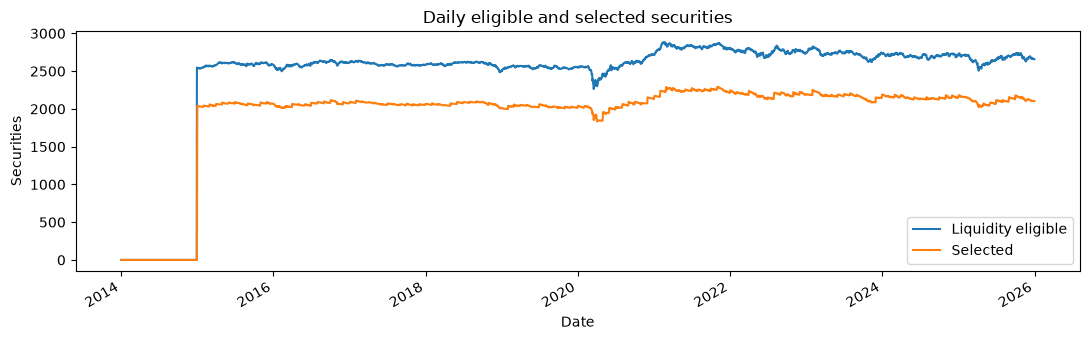

In [7]:
universe_audit = build_universe(RAW, OUT)
display(pd.Series({k: universe_audit[k] for k in ['raw_candidate_SIDs',
    'selected_SIDs', 'membership_cells']}))
truncation = pd.DataFrame(universe_audit['truncation'])
display(truncation)
assert truncation.differing_cells.eq(0).all()
counts = pd.read_csv(OUT / 'universe_daily_counts.csv', parse_dates=['date']).set_index('date')
display(counts.groupby(counts.index.year).mean().round().astype(int))
counts[['Liquidity eligible', 'Selected']].plot(figsize=(11, 3.5),
    title='Daily eligible and selected securities', ylabel='Securities', xlabel='Date')
plt.tight_layout()
plt.show()


## 8. Prices, Delistings and Labels
Compound source returns in float64 within dated security segments; keep missing quotes missing. Handle terminal payoffs separately, without double-counting CIZ returns. Construct next-close ten-session labels and censor the last eleven signals.

calendar_sessions                                         3018
SID_union                                                 4366
quarantined_bars                                             2
quarantined_eligible_bars                                    1
last_11_targets_censored                                  True
price_precision_policy       canonical_total_return_float64_v1
dtype: object

,date,sid,quarantined
0,20141216,CNA:160216:01,True
1,20230605,CNA:039405:01,True


events
source               status                              
CIZ embedded return  NaN                              154
SIZ delisting ledger reported_terminal_return        1153
                     source_observation_preserved      43
                     unresolved_terminal_return        58

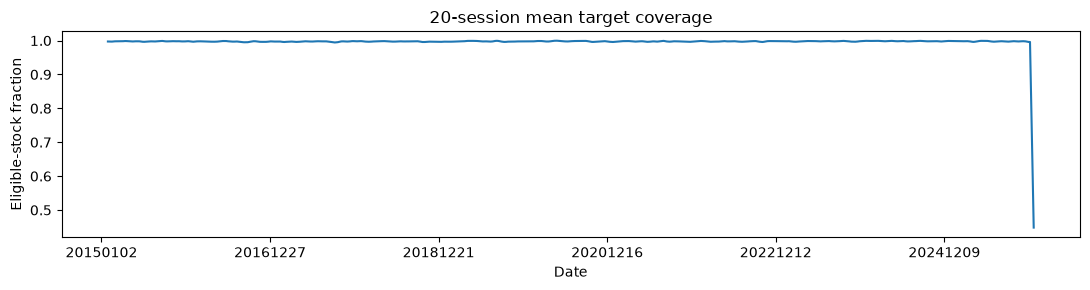

In [8]:
snapshot = publish_strategy_snapshot(RAW, OUT, DATA_ROOT)
price_audit, coverage = audit_published_prices(snapshot)
assert price_audit['price_precision_policy'] == PRICE_PRECISION_POLICY
display(pd.Series({k: price_audit[k] for k in ['calendar_sessions', 'SID_union',
    'quarantined_bars', 'quarantined_eligible_bars', 'last_11_targets_censored', 'price_precision_policy']}))
coverage.to_csv(OUT / 'target_coverage.csv', index_label='date')
display(pd.read_csv(snapshot / 'metadata/ohlc_quarantine.csv'))
terminal = pd.read_parquet(snapshot / 'metadata/terminal_events.parquet')
display(terminal.groupby(['source', 'status'], dropna=False).size().rename('events').to_frame()
    if 'status' in terminal else terminal.groupby('source').size().rename('events').to_frame())
coverage.loc['20150101':, 'coverage'].rolling(20).mean().plot(figsize=(11, 3),
    title='20-session mean target coverage', ylabel='Eligible-stock fraction', xlabel='Date')
plt.tight_layout()
plt.show()


## 9. Supplementary Vendor Coverage
Sina turnover/VWAP is excluded from strategy inputs because historical coverage is incomplete. Audit same-vendor amount/volume pairs and dated CRSP OHLC correspondence.

In [9]:
tickers = ('AAPL', 'JPM', 'XOM', 'HD', 'JNJ', 'BAC', 'PG', 'UNH', 'WMT', 'MSFT',
           'TWTR', 'COIN', 'UBER', 'PLTR', 'ABNB', 'AMZN', 'NVDA', 'GOOGL', 'META',
           'ATVI', 'TSLA', 'FB', 'AIR', 'SPY')
sina_summary, sina_failures = probe_sina(RAW, OUT, tickers,
    response_directory=DATA_ROOT / 'raw/sina' / OUT.name)
display(sina_summary)
display(pd.DataFrame(sina_failures))


,ticker,period_rows,positive_amount,crsp_price_matches,accepted_vwap,first_positive_amount,first_accepted_vwap,volume_median_ratio
0,AAPL,3017,2132,2896,2097,2017-07-11 00:00:00,2017-07-11 00:00:00,1.000309
1,JPM,3017,2132,2996,2107,2017-07-11 00:00:00,2017-07-25 00:00:00,1.000000
2,XOM,3017,2132,2993,2105,2017-07-11 00:00:00,2017-07-25 00:00:00,1.000000
3,HD,3017,2132,2993,2106,2017-07-11 00:00:00,2017-08-09 00:00:00,1.000000
4,JNJ,3017,2132,2994,2099,2017-07-11 00:00:00,2017-07-26 00:00:00,1.000000
5,BAC,3017,2132,3005,2118,2017-07-11 00:00:00,2017-07-11 00:00:00,1.000000
6,PG,3017,2132,2999,2108,2017-07-11 00:00:00,2017-07-14 00:00:00,1.000000
7,UNH,3017,2132,2994,2109,2017-07-11 00:00:00,2017-08-09 00:00:00,1.000000
8,WMT,3017,2132,2997,2108,2017-07-11 00:00:00,2017-07-13 00:00:00,1.000000
9,MSFT,3017,2132,2940,2097,2017-07-11 00:00:00,2017-07-12 00:00:00,1.000863


""


## 10. Publish
Verify unchanged source hashes, save aggregate audits, then activate the completed dataset for the strategy notebook.

In [10]:
for row in sources.itertuples():
    path = (QUARTERLY if row.file == QUARTERLY.name else
            ANNUAL if row.file == ANNUAL.name else next(RAW.rglob(row.file)))
    assert digest(path) == row.sha256, row.file
PUBLIC = ROOT / 'results/raw_data_preparation'
PUBLIC.mkdir(parents=True, exist_ok=True)
for name in ['source_inventory.csv', 'market_quality.csv', 'fundamental_audit.json',
             'industry_audit.json', 'universe_audit.json', 'universe_daily_counts.csv',
             'target_coverage.csv', 'sina_validation.csv']:
    (PUBLIC / name).write_bytes((OUT / name).read_bytes())
(OUT / 'complete.json').write_text(json.dumps({'complete': True,
    'research_accepted': False, 'price_precision_policy': PRICE_PRECISION_POLICY}, indent=2))
activate_snapshot(DATA_ROOT, snapshot, OUT)
print('Dataset:', snapshot)
print('Strategy input activated:', DATA_ROOT / 'processed/latest_snapshot.json')


Dataset: /Users/utastn/Desktop/Files/学习资料/NUS/DSA5205/DSA5205_Project2/release/DSA5205_Project2_Freya/data/processed/wrds_20261111_134234_590623/research_snapshot
Strategy input activated: /Users/utastn/Desktop/Files/学习资料/NUS/DSA5205/DSA5205_Project2/release/DSA5205_Project2_Freya/data/processed/latest_snapshot.json
